# Experiment 7: Logical and Probabilistic Reasoning

**Aim:** To implement basic Propositional Logic, First-Order Logic and probability based reasoning using Python.

**Name:**  
**Roll No.:**  
**Date:**  

## Exercise 1: Propositional Logic

Rule: *"If it rains, then the road is wet"*

Let  
P = It rains  
Q = The road is wet  

The rule becomes **P → Q** (implication).  
P → Q is false only when P is true and Q is false. It is same as **(¬P ∨ Q)**, so I will check both ways to verify.

In [23]:
import itertools

def implies(p, q):
    return (not p) or q

print("P (Rain) | Q (Road Wet) | P -> Q | (not P) or Q | Match?")

all_match = True
for p, q in itertools.product([True, False], repeat=2):
    imp = implies(p, q)
    equiv = (not p) or q          # equivalent form
    same = (imp == equiv)
    if not same:
        all_match = False
    print(f"{str(p):8} | {str(q):12} | {str(imp):6} | {str(equiv):12} | {same}")

print()
print("Both forms give same result for all rows:", all_match)

P (Rain) | Q (Road Wet) | P -> Q | (not P) or Q | Match?
True     | True         | True   | True         | True
True     | False        | False  | False        | True
False    | True         | True   | True         | True
False    | False        | True   | True         | True

Both forms give same result for all rows: True


**Verification / Observation:**  
- The only row where P → Q is False is when it rains (P = True) but the road is not wet (Q = False). This makes sense because that case breaks the rule.
- If it does not rain, the rule is True no matter what Q is (road can be wet due to other reasons).
- P → Q and (¬P ∨ Q) have the same truth table, so the result is verified.

## Exercise 2: First-Order Logic

Statements:
1. All humans are mortal → ∀x (Human(x) → Mortal(x))
2. Socrates is a human → Human(Socrates)


In [ ]:
humans = {"Socrates"}

# Rule: for all x, Human(x) -> Mortal(x)
def is_mortal(x, facts):
    if x in facts:
        return True
    return False

mortals = set()
for person in humans:
    if is_mortal(person, humans):
        mortals.add(person)

print("Known humans :", humans)
print("Derived mortals :", mortals)
print()

query = "Socrates"
if query in mortals:
    print(f"Yes, {query} is mortal.")
else:
    print(f"Cannot say that {query} is mortal.")

query2 = "Zeus"
print()
print(f"Is {query2} mortal? ->", "Yes" if query2 in mortals else "Cannot be derived from the given facts")

Known humans : {'Socrates'}
Derived mortals : {'Socrates'}

Yes, Socrates is mortal.

Is Zeus mortal? -> Cannot be derived from the given facts


## Exercise 3: Probability of Events

I made a small dataset of 20 students with two things:  
- **Attended** the classes (Yes/No)  
- **Result** (Pass/Fail)

Events:  
- A = Student passed  
- B = Student attended classes

In [22]:
import pandas as pd

data = [
    ("Yes","Pass"), ("Yes","Pass"), ("Yes","Pass"), ("Yes","Pass"), ("Yes","Pass"),
    ("Yes","Pass"), ("Yes","Pass"), ("Yes","Pass"), ("Yes","Pass"), ("Yes","Pass"),
    ("Yes","Fail"), ("Yes","Fail"),
    ("No","Pass"),  ("No","Pass"),  ("No","Pass"),
    ("No","Fail"),  ("No","Fail"), ("No","Fail"), ("No","Fail"), ("No","Fail"),
]

df = pd.DataFrame(data, columns=["Attended", "Result"])
print(df.head(10))
print("\nTotal students =", len(df))
print()
print(pd.crosstab(df["Attended"], df["Result"], margins=True))

  Attended Result
0      Yes   Pass
1      Yes   Pass
2      Yes   Pass
3      Yes   Pass
4      Yes   Pass
5      Yes   Pass
6      Yes   Pass
7      Yes   Pass
8      Yes   Pass
9      Yes   Pass

Total students = 20

Result    Fail  Pass  All
Attended                 
No           5     3    8
Yes          2    10   12
All          7    13   20


In [25]:
total = len(df)

A = df["Result"] == "Pass"
B = df["Attended"] == "Yes"

P_A = A.sum() / total
P_B = B.sum() / total

# joint probability
P_A_and_B = (A & B).sum() / total

# union P(A or B) using direct counting
P_A_or_B = (A | B).sum() / total


print("P(A) = P(Pass) =", P_A)
print("P(B) = P(Attended) =", P_B)
print("P(A and B) = P(Pass & Attended) =", P_A_and_B)
print("P(A or B) =", round(P_A_or_B, 4))


P(A) = P(Pass) = 0.65
P(B) = P(Attended) = 0.6
P(A and B) = P(Pass & Attended) = 0.5
P(A or B) = 0.75


## Exercise 4: Conditional Probability

Using the same dataset:

- P(A | B) = P(A ∩ B) / P(B) → probability of passing given the student attended  
- P(B | A) = P(A ∩ B) / P(A) → probability that student attended given he passed

In [26]:
P_A_given_B = P_A_and_B / P_B
P_B_given_A = P_A_and_B / P_A

print(f"P(A | B) = P(Pass | Attended) = {P_A_given_B:.4f}")
print(f"P(B | A) = P(Attended | Pass) = {P_B_given_A:.4f}")

P(A | B) = P(Pass | Attended) = 0.8333
P(B | A) = P(Attended | Pass) = 0.7692


## Exercise 5: Bayes' Theorem

Bayes' theorem:

P(D | Pos) = [ P(Pos | D) · P(D) ] / P(Pos)


In [6]:
# given probabilities
p_disease = 0.01
p_pos_given_disease = 0.95
p_pos_given_no_disease = 0.05

def bayes(p_d, sens, fpr):
    p_no_d = 1 - p_d
    # total probability of positive test
    p_pos = sens * p_d + fpr * p_no_d
    # posterior
    return (sens * p_d) / p_pos, p_pos

posterior, p_pos = bayes(p_disease, p_pos_given_disease, p_pos_given_no_disease)

print("P(Disease)                =", p_disease)
print("P(Positive)               =", round(p_pos, 4))
print("P(Disease | Positive)     =", round(posterior, 4))
print(f"i.e. about {posterior*100:.2f} % chance of having the disease after a positive test")

P(Disease)                = 0.01
P(Positive)               = 0.059
P(Disease | Positive)     = 0.161
i.e. about 16.10 % chance of having the disease after a positive test


**Observation:** Even though the test is 95% accurate, the probability of actually having the disease after a positive result is only around 16%. This is because the disease is very rare (1%), so most of the positive results come from healthy people (false positives).

## Exercise 6: Visualization

First I plot the probabilities calculated above. Then I change one input probability (the prior P(Disease)) and see how the posterior changes.

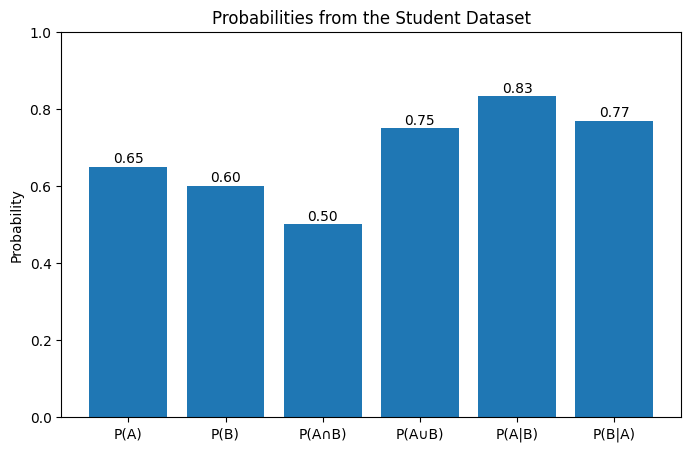

In [ ]:
import matplotlib.pyplot as plt

labels = ["P(A)", "P(B)", "P(A∩B)", "P(A∪B)", "P(A|B)", "P(B|A)"]
values = [P_A, P_B, P_A_and_B, P_A_or_B, P_A_given_B, P_B_given_A]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values)
for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.01, f"{v:.2f}", ha="center")
plt.ylim(0, 1)
plt.ylabel("Probability")
plt.title("Probabilities from the Student Dataset")
plt.show()

Prior = 0.01  ->  P(D|Pos) = 0.161
Prior = 0.10  ->  P(D|Pos) = 0.6786


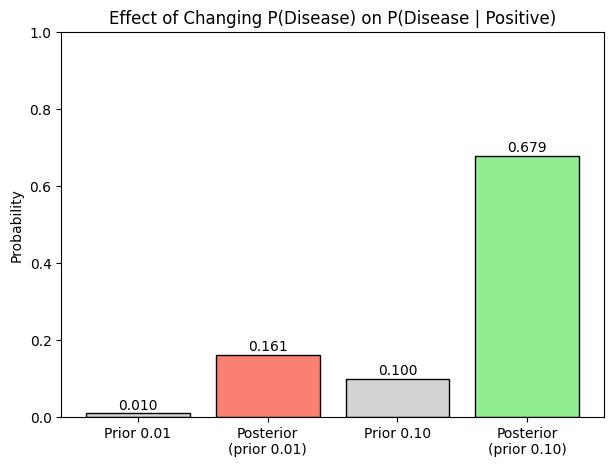

In [8]:
# graph 2: Bayes result with original prior and modified prior
original_prior = 0.01
new_prior = 0.10          # modified input (changed from 0.01 to 0.10)

post_original, _ = bayes(original_prior, p_pos_given_disease, p_pos_given_no_disease)
post_new, _ = bayes(new_prior, p_pos_given_disease, p_pos_given_no_disease)

print("Prior = 0.01  ->  P(D|Pos) =", round(post_original, 4))
print("Prior = 0.10  ->  P(D|Pos) =", round(post_new, 4))

plt.figure(figsize=(7, 5))
names = ["Prior 0.01", "Posterior\n(prior 0.01)", "Prior 0.10", "Posterior\n(prior 0.10)"]
vals = [original_prior, post_original, new_prior, post_new]
cols = ["lightgray", "salmon", "lightgray", "lightgreen"]
b = plt.bar(names, vals, color=cols, edgecolor="black")
for bar, v in zip(b, vals):
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.01, f"{v:.3f}", ha="center")
plt.ylim(0, 1)
plt.ylabel("Probability")
plt.title("Effect of Changing P(Disease) on P(Disease | Positive)")
plt.show()

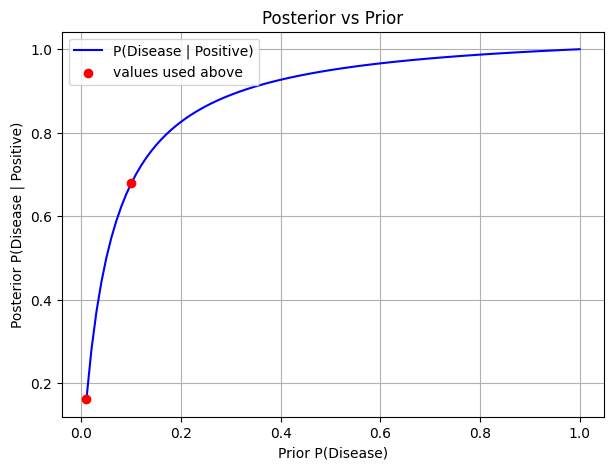

In [9]:
# graph 3: how the posterior changes for many values of the prior
priors = [i / 100 for i in range(1, 101)]
posts = [bayes(p, p_pos_given_disease, p_pos_given_no_disease)[0] for p in priors]

plt.figure(figsize=(7, 5))
plt.plot(priors, posts, color="blue", label="P(Disease | Positive)")
plt.scatter([original_prior, new_prior], [post_original, post_new], color="red", zorder=5, label="values used above")
plt.xlabel("Prior P(Disease)")
plt.ylabel("Posterior P(Disease | Positive)")
plt.title("Posterior vs Prior")
plt.grid(True)
plt.legend()
plt.show()